# SignBridge AI — WL-BISINDO
Tahap notebook ini mencakup persiapan dataset, EDA, preprocessing, ekstraksi landmark MediaPipe, pembagian data, dan definisi model LSTM. **Training dan evaluasi belum termasuk.**

> Dataset WL-BISINDO digunakan untuk kosakata BISINDO, bukan Kata Kolok. Periksa struktur folder dan label yang ditemukan sebelum melanjutkan.

## 1. Import Libraries

In [1]:
# Instalasi (jalankan di terminal VS Code, bukan di cell ini):
# python -m pip install opencv-python mediapipe tensorflow scikit-learn pandas numpy matplotlib tqdm

from pathlib import Path
import re
import random, warnings, pickle
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mediapipe as mp
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, top_k_accuracy_score
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__, "| OpenCV:", cv2.__version__, "| MediaPipe:", mp.__version__)

TensorFlow: 2.19.1 | OpenCV: 5.0.0 | MediaPipe: 0.10.9


C:\Users\Ryan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Konfigurasi Path dan Parameter

In [2]:
# Sesuaikan path dengan lokasi dataset yang sudah diekstrak.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_DIR = PROJECT_DIR / "data" / "raw" / "WL-BISINDO"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "landmarks"
MODEL_DIR = PROJECT_DIR / "models"
for folder in (PROCESSED_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

NUM_FRAMES = 30
TEST_SIZE = 0.20
VAL_SIZE_FROM_REMAINDER = 0.20
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
MIN_DETECTION_CONFIDENCE = 0.5
MIN_TRACKING_CONFIDENCE = 0.5

print("Dataset path:", DATASET_DIR.resolve())
print("Folder ditemukan:", DATASET_DIR.exists())

Dataset path: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\data\raw\WL-BISINDO
Folder ditemukan: True


## 3. Memuat Dataset WL-BISINDO

In [3]:
# Lokasi folder dataset
video_paths = sorted(
    p for p in DATASET_DIR.rglob("*.mp4")
    if p.is_file()
)

# Pola nama file:
# signer0_label0_sample1.mp4
pattern = re.compile(
    r"signer(\d+)_label(\d+)_sample(\d+)\.mp4$",
    re.IGNORECASE
)

records = []
invalid_files = []

for path in video_paths:
    match = pattern.fullmatch(path.name)

    if match:
        signer_id = int(match.group(1))
        label_id = int(match.group(2))
        sample_id = int(match.group(3))

        records.append({
            "video_path": str(path),
            "signer_id": signer_id,
            "label_id": label_id,
            "sample_id": sample_id
        })
    else:
        invalid_files.append(path.name)

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "Tidak ada file yang sesuai dengan pola nama WL-BISINDO. "
        "Periksa DATASET_DIR dan nama file."
    )

print("Jumlah video valid:", len(df))
print("Jumlah signer:", df["signer_id"].nunique())
print("Jumlah label:", df["label_id"].nunique())
print("Jumlah file tidak sesuai pola:", len(invalid_files))

display(df.head(10))

Jumlah video valid: 1600
Jumlah signer: 5
Jumlah label: 32
Jumlah file tidak sesuai pola: 0


,video_path,signer_id,label_id,sample_id
0,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,1
1,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,10
2,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,2
3,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,3
4,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,4
5,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,5
6,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,6
7,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,7
8,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,8
9,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,9


## 4. Exploratory Data Analysis (EDA)

,jumlah_video
label_id,
0,50
1,50
2,50
3,50
4,50
5,50
6,50
7,50
8,50


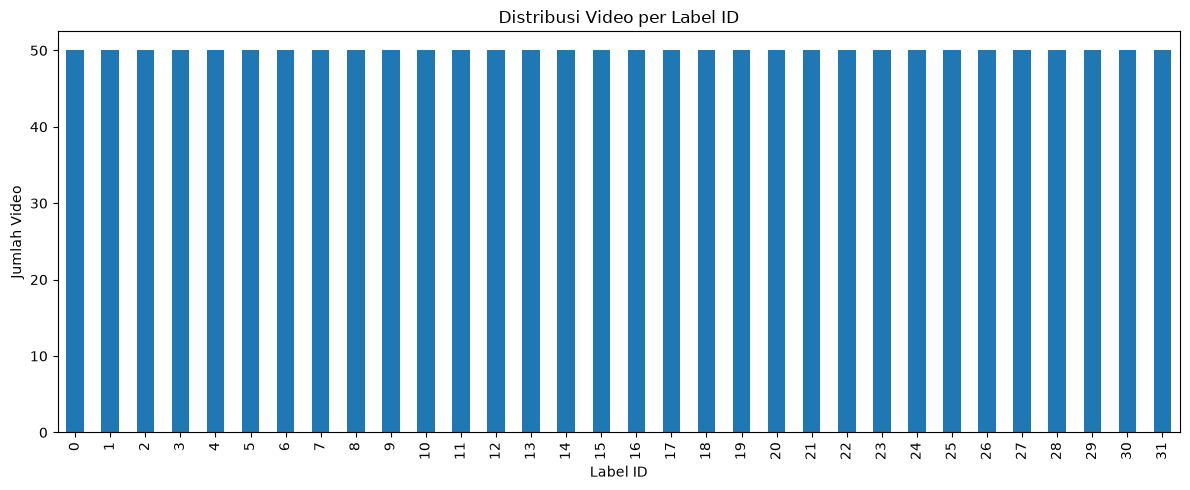

In [4]:

class_counts = df["label_id"].value_counts().sort_index()

display(
    class_counts.rename("jumlah_video").to_frame()
)

class_counts.plot(
    kind="bar",
    figsize=(12, 5),
    title="Distribusi Video per Label ID"
)

plt.xlabel("Label ID")
plt.ylabel("Jumlah Video")
plt.tight_layout()
plt.show()

## 5. Visualisasi Sampel Video

Signer ID: 1
Label ID: 8
Sample ID: 6


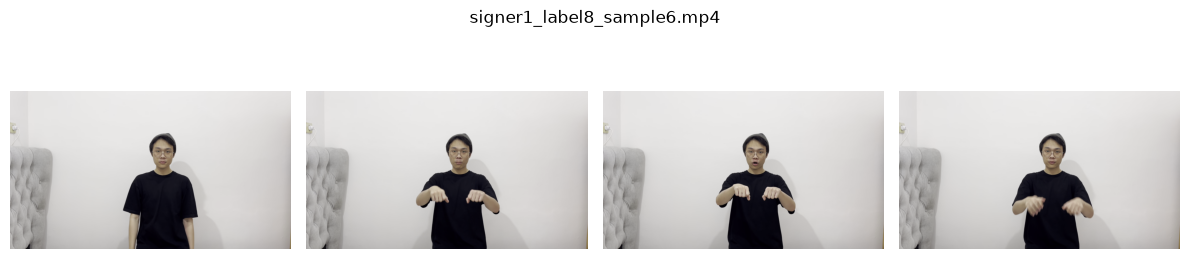

In [5]:
def show_video_frames(video_path, n_frames=6):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        cap.release()
        print("Video tidak dapat dibuka:", video_path)
        return
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < 1:
        cap.release(); print("Video tidak memiliki frame."); return
    indices = np.linspace(0, total - 1, min(n_frames, total), dtype=int)
    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()
        if ok: frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
    if not frames:
        print("Tidak ada frame terbaca."); return
    fig, axes = plt.subplots(1, len(frames), figsize=(3*len(frames), 3))
    if len(frames) == 1: axes = [axes]
    for ax, frame in zip(axes, frames):
        ax.imshow(frame); ax.axis("off")
    fig.suptitle(Path(video_path).name); plt.tight_layout(); plt.show()


sample = df.sample(1, random_state=SEED).iloc[0]

print("Signer ID:", sample["signer_id"])
print("Label ID:", sample["label_id"])
print("Sample ID:", sample["sample_id"])

show_video_frames(sample["video_path"])

## 6. Validasi Dataset

In [6]:
validation_rows = []

for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Memeriksa video"
):
    cap = cv2.VideoCapture(row.video_path)

    opened = cap.isOpened()
    frame_count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    ) if opened else 0

    fps = float(
        cap.get(cv2.CAP_PROP_FPS)
    ) if opened else 0.0

    cap.release()

    validation_rows.append({
        "video_path": row.video_path,
        "signer_id": row.signer_id,
        "label_id": row.label_id,
        "sample_id": row.sample_id,
        "is_readable": bool(opened and frame_count > 0),
        "frame_count": frame_count,
        "fps": fps
    })

validation_df = pd.DataFrame(validation_rows)

display(validation_df.head())

print(
    "Video bermasalah:",
    int((~validation_df["is_readable"]).sum())
)

df = validation_df.loc[
    validation_df["is_readable"]
].reset_index(drop=True)

print("Jumlah video valid:", len(df))

Memeriksa video: 100%|██████████| 1600/1600 [00:39<00:00, 40.79it/s]


,video_path,signer_id,label_id,sample_id,is_readable,frame_count,fps
0,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,1,True,81,26.413043
1,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,10,True,88,26.925038
2,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,2,True,67,28.309859
3,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,3,True,73,27.703985
4,c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTE...,0,0,4,True,84,27.391304


Video bermasalah: 0
Jumlah video valid: 1600


## 7. Preprocessing Video

In [7]:
def sample_video_frames(video_path, num_frames=NUM_FRAMES):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        print("Video tidak bisa dibuka:", video_path)
        return None

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames < 1:
        cap.release()
        return None

    # Baca semua frame terlebih dahulu
    all_frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        all_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()

    if len(all_frames) == 0:
        return None

    # Gunakan linspace agar index bisa duplikat (video pendek di-repeat otomatis)
    indices = np.linspace(0, len(all_frames) - 1, num_frames).astype(int)
    frames = [all_frames[i] for i in indices]

    return np.asarray(frames, dtype=np.uint8)

test_frames = sample_video_frames(df.iloc[0].video_path)
print("Shape frame:", None if test_frames is None else test_frames.shape)


Shape frame: (30, 720, 1280, 3)


## 8. Ekstraksi Fitur Landmark MediaPipe

In [8]:
# Baseline: pose (33 landmark) + tangan kiri (21) + tangan kanan (21).
# Setiap landmark memiliki x, y, z => 225 fitur per frame.
mp_holistic = mp.solutions.holistic
FEATURES_PER_FRAME = (33 + 21 + 21) * 3

def landmarks_array(landmarks, n_points):
    if landmarks is None:
        return np.zeros((n_points, 3), dtype=np.float32)
    return np.array([[lm.x, lm.y, lm.z] for lm in landmarks.landmark], dtype=np.float32)

def extract_landmarks(frames):
    sequence = []
    with mp_holistic.Holistic(
        static_image_mode=False, model_complexity=1,
        smooth_landmarks=True, enable_segmentation=False,
        refine_face_landmarks=False,
        min_detection_confidence=MIN_DETECTION_CONFIDENCE,
        min_tracking_confidence=MIN_TRACKING_CONFIDENCE
    ) as holistic:
        for frame in frames:
            result = holistic.process(frame)
            pose = landmarks_array(result.pose_landmarks, 33).flatten()
            left = landmarks_array(result.left_hand_landmarks, 21).flatten()
            right = landmarks_array(result.right_hand_landmarks, 21).flatten()
            sequence.append(np.concatenate([pose, left, right]))
    sequence = np.asarray(sequence, dtype=np.float32)

    # Pastikan shape selalu (NUM_FRAMES, FEATURES_PER_FRAME)
    n = sequence.shape[0]
    if n < NUM_FRAMES:
        # Pad dengan frame terakhir jika kurang dari NUM_FRAMES
        pad = np.tile(sequence[-1:], (NUM_FRAMES - n, 1))
        sequence = np.concatenate([sequence, pad], axis=0)
    elif n > NUM_FRAMES:
        # Trim jika lebih dari NUM_FRAMES
        sequence = sequence[:NUM_FRAMES]

    assert sequence.shape == (NUM_FRAMES, FEATURES_PER_FRAME), f"Shape fitur tidak sesuai: {sequence.shape}"
    return sequence

if test_frames is not None:
    sample_features = extract_landmarks(test_frames)
    print("Shape landmark:", sample_features.shape)


Shape landmark: (30, 225)


## 9. Ekstraksi Fitur Seluruh Dataset

In [9]:
# Tahap ini bisa memerlukan waktu. Simpan hasilnya agar tidak perlu ekstraksi ulang.
X_list, y_list, path_list, failed_paths = [], [], [], []
for row in tqdm(df.itertuples(index=False), total=len(df), desc="Ekstraksi landmark"):
    frames = sample_video_frames(row.video_path)
    if frames is None:
        failed_paths.append(row.video_path); continue
    try:
        X_list.append(extract_landmarks(frames))
        y_list.append(row.label_id)
        path_list.append(row.video_path)
    except Exception as exc:
        failed_paths.append(row.video_path)
        print(f"Gagal: {row.video_path} | {exc}")

if len(X_list) == 0:
    raise RuntimeError("Tidak ada fitur berhasil diekstraksi.")
X = np.stack(X_list).astype(np.float32)
y_text = np.asarray(y_list, dtype=np.int32)
np.save(PROCESSED_DIR / "X_landmarks.npy", X)
np.save(PROCESSED_DIR / "y_labels.npy", y_text)
pd.DataFrame({"video_path": path_list, "label": y_text}).to_csv(
    PROCESSED_DIR / "processed_manifest.csv", index=False)
print("X:", X.shape, "| y:", y_text.shape, "| gagal:", len(failed_paths))

Ekstraksi landmark: 100%|██████████| 1600/1600 [1:06:06<00:00,  2.48s/it]

X: (1600, 30, 225) | y: (1600,) | gagal: 0


## 10. Label Encoding

In [10]:
# ============================================
# CELL 10 - LABEL ENCODING & PEMETAAN GLOSS
# ============================================

import numpy as np
from sklearn.preprocessing import LabelEncoder

# Pemetaan ID label WL-BISINDO ke nama isyarat
LABEL_TO_GLOSS = {
    0: "Air",
    1: "Belajar",
    2: "Cari",
    3: "Hari",
    4: "Ingat",
    5: "Lagi",
    6: "Maaf",
    7: "Makan",
    8: "Motor",
    9: "Saya",
    10: "Terima kasih",
    11: "Tuli",
    12: "Apa",
    13: "Siapa",
    14: "Kapan",
    15: "Di mana",
    16: "Mengapa",
    17: "Bagaimana",
    18: "Merah",
    19: "Kuning",
    20: "Hijau",
    21: "Hitam",
    22: "Dengar",
    23: "Berangkat",
    24: "Datang",
    25: "Teman",
    26: "Keluarga",
    27: "Rumah",
    28: "Pagi",
    29: "Siang",
    30: "Sore",
    31: "Malam"
}

# ✅ PERBAIKAN: Buat label_encoder dari y_text (hasil ekstraksi Cell 9)
# y_text berisi integer label_id (0..31) sebagai np.int32
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)   # ← fit sekaligus transform

NUM_CLASSES = len(label_encoder.classes_)

# Pastikan seluruh label mempunyai nama gloss
missing_labels = [
    int(label)
    for label in label_encoder.classes_
    if int(label) not in LABEL_TO_GLOSS
]

if missing_labels:
    raise ValueError(
        f"ID label belum memiliki nama gloss: {missing_labels}"
    )

# Nama kelas mengikuti urutan label_encoder
gloss_names = [
    LABEL_TO_GLOSS[int(label)]
    for label in label_encoder.classes_
]

print("Jumlah kelas:", NUM_CLASSES)
print("Nama kelas:")
for label_id, gloss in zip(label_encoder.classes_, gloss_names):
    print(f"  {int(label_id):2d}: {gloss}")


Jumlah kelas: 32
Nama kelas:
   0: Air
   1: Belajar
   2: Cari
   3: Hari
   4: Ingat
   5: Lagi
   6: Maaf
   7: Makan
   8: Motor
   9: Saya
  10: Terima kasih
  11: Tuli
  12: Apa
  13: Siapa
  14: Kapan
  15: Di mana
  16: Mengapa
  17: Bagaimana
  18: Merah
  19: Kuning
  20: Hijau
  21: Hitam
  22: Dengar
  23: Berangkat
  24: Datang
  25: Teman
  26: Keluarga
  27: Rumah
  28: Pagi
  29: Siang
  30: Sore
  31: Malam


## 11. Pembagian Data Train, Validation, dan Test

In [11]:
# Pembagian dilakukan pada level video, bukan frame.
# Ini split stratified per video; belum menjamin signer-independent.
indices = np.arange(len(y))
counts = pd.Series(y).value_counts()
stratify_all = y if counts.min() >= 3 else None

train_val_idx, test_idx = train_test_split(
    indices, test_size=TEST_SIZE, random_state=SEED, stratify=stratify_all
)
train_val_y = y[train_val_idx]
stratify_tv = train_val_y if pd.Series(train_val_y).value_counts().min() >= 2 else None
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=VAL_SIZE_FROM_REMAINDER,
    random_state=SEED, stratify=stratify_tv
)
X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (1024, 30, 225) (1024,)
Validation: (256, 30, 225) (256,)
Test: (320, 30, 225) (320,)


## 12. Data Augmentation (Opsional)

In [12]:
# Augmentasi belum diaktifkan pada baseline awal.
# Noise kecil pada landmark dapat diuji nanti hanya pada data train, setelah
# memastikan augmentasi tidak mengubah arti isyarat.
def add_landmark_noise(sequence, std=0.005):
    return sequence + np.random.normal(0, std, sequence.shape).astype(np.float32)

print("Baseline menggunakan fitur asli tanpa augmentasi.")

Baseline menggunakan fitur asli tanpa augmentasi.


## 13. Arsitektur Model LSTM

In [13]:
INPUT_SHAPE = (NUM_FRAMES, FEATURES_PER_FRAME)

def build_lstm_model(input_shape, num_classes):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Masking(mask_value=0.0),
        layers.LSTM(128, return_sequences=True),
        layers.Dropout(0.30),
        layers.LSTM(64),
        layers.Dropout(0.30),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(num_classes, activation="softmax")
    ])

model = build_lstm_model(INPUT_SHAPE, NUM_CLASSES)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 30, 225)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 128)        │       181,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 236,896 (925.38 KB)

 Trainable params: 236,896 (925.38 KB)

 Non-trainable params: 0 (0.00 B)

## 14. Compile Model

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model berhasil dikompilasi. Tahap berikutnya adalah training dan evaluasi.")

Model berhasil dikompilasi. Tahap berikutnya adalah training dan evaluasi.


In [15]:
SEQUENCE_LENGTH = NUM_FRAMES        # 30
FEATURE_DIM     = FEATURES_PER_FRAME  # 225 (pose+tangan mediapipe)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def build_gesture_model(num_classes, seq_len, feat_dim):
    model = Sequential([
        Input(shape=(seq_len, feat_dim)),

        LSTM(128, return_sequences=True),
        BatchNormalization(),
        Dropout(0.3),

        LSTM(64, return_sequences=False),
        BatchNormalization(),
        Dropout(0.3),

        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(num_classes, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_gesture_model(NUM_CLASSES, SEQUENCE_LENGTH, FEATURE_DIM)
model.summary()

callbacks = [
    EarlyStopping(
        monitor='val_loss',       
        patience=10,               
        restore_best_weights=True, 
        min_delta=1e-4,            
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',        
        patience=5,               
        factor=0.5,
        min_lr=1e-6,
        min_delta=1e-4,            
        verbose=1
    ),
    ModelCheckpoint(
        str(MODEL_DIR / "best_gesture_model.keras"),
        monitor='val_loss',        
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,          
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

print("\n✅ Training selesai.")
print(f"   Epoch berhenti  : {len(history.history['accuracy'])}/100")
print(f"   Final train acc : {history.history['accuracy'][-1]:.4f}")
print(f"   Final val acc   : {history.history['val_accuracy'][-1]:.4f}")
print(f"   Best val loss   : {min(history.history['val_loss']):.4f}")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 128)        │       181,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,384 (954.62 KB)

 Trainable params: 243,744 (952.12 KB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/100
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1119 - loss: 3.5217
Epoch 1: val_loss improved from None to 3.36821, saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras

Epoch 1: finished saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.1123 - loss: 3.5055 - val_accuracy: 0.0547 - val_loss: 3.3682 - learning_rate: 0.0010
Epoch 2/100
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1472 - loss: 3.0030
Epoch 2: val_loss improved from 3.36821 to 3.31703, saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras

Epoch 2: finished saving model to c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.1484 - loss: 2.9891 - v

  Test Loss     : 0.2021
  Test Accuracy : 0.9375 (93.75%)

Classification Report:

              precision    recall  f1-score   support

         Air       1.00      1.00      1.00        10
     Belajar       1.00      1.00      1.00        10
        Cari       1.00      1.00      1.00        10
        Hari       1.00      1.00      1.00        10
       Ingat       1.00      0.90      0.95        10
        Lagi       0.91      1.00      0.95        10
        Maaf       0.77      1.00      0.87        10
       Makan       1.00      0.80      0.89        10
       Motor       1.00      0.90      0.95        10
        Saya       1.00      1.00      1.00        10
Terima kasih       1.00      1.00      1.00        10
        Tuli       1.00      1.00      1.00        10
         Apa       0.89      0.80      0.84        10
       Siapa       1.00      1.00      1.00        10
       Kapan       0.71      1.00      0.83        10
     Di mana       0.86      0.60      0.71        

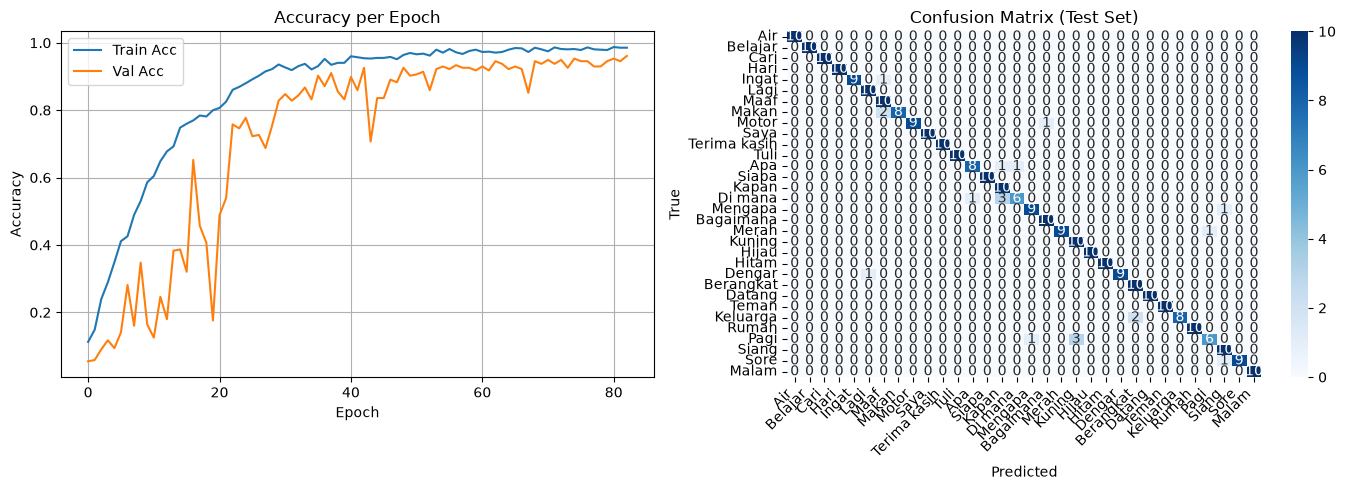


✅ Evaluasi selesai.
   Epoch berhenti   : 83/100
   Final train acc  : 0.9854
   Final val acc    : 0.9609
   Best val loss    : 0.1163
   Test accuracy    : 0.9375


In [16]:
# ============================================
# EVALUASI MODEL — dengan nama gloss BISINDO
# ============================================

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# --- Prediksi pada data test ---
y_pred_proba = model.predict(X_test, verbose=0)
y_pred       = np.argmax(y_pred_proba, axis=1)

# --- Test Loss & Accuracy ---
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("=" * 45)
print(f"  Test Loss     : {test_loss:.4f}")
print(f"  Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)")
print("=" * 45)

# --- Classification Report (dengan nama gloss) ---
print("\nClassification Report:\n")
print(classification_report(
    y_test, y_pred,
    target_names=gloss_names   # ✅ gunakan nama gloss
))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training history
axes[0].plot(history.history["accuracy"],    label="Train Acc")
axes[0].plot(history.history["val_accuracy"], label="Val Acc")
axes[0].set_title("Accuracy per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Confusion Matrix (dengan nama gloss)
sns.heatmap(
    cm,
    annot=True, fmt="d",
    xticklabels=gloss_names,
    yticklabels=gloss_names,
    ax=axes[1],
    cmap="Blues"
)
axes[1].set_title("Confusion Matrix (Test Set)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# --- Ringkasan akhir ---
print(f"\n✅ Evaluasi selesai.")
print(f"   Epoch berhenti   : {len(history.history['accuracy'])}/100")
print(f"   Final train acc  : {history.history['accuracy'][-1]:.4f}")
print(f"   Final val acc    : {history.history['val_accuracy'][-1]:.4f}")
print(f"   Best val loss    : {min(history.history['val_loss']):.4f}")
print(f"   Test accuracy    : {test_acc:.4f}")


## 15. Signer-Independent Evaluation

In [17]:
# ============================================
# SIGNER-INDEPENDENT EVALUATION
# ============================================
"""
Menguji model pada signer yang TIDAK digunakan saat training.
Strategi: leave-one-signer-out evaluation.
"""

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# Pastikan df memiliki kolom signer_id dan data terindeks
# Ambil signer unik
signer_ids = sorted(df["signer_id"].unique())
print(f"Signer tersedia: {signer_ids}")
print(f"Jumlah signer  : {len(signer_ids)}\n")

results_per_signer = []

for held_out_signer in signer_ids:
    # Mask untuk signer yang di-hold-out
    mask_test  = df["signer_id"] == held_out_signer
    mask_train = ~mask_test

    idx_train = df.index[mask_train].tolist()
    idx_test  = df.index[mask_test].tolist()

    if len(idx_test) == 0:
        continue

    X_si_train = X[idx_train]
    y_si_train = y[idx_train]
    X_si_test  = X[idx_test]
    y_si_test  = y[idx_test]

    # Latih ulang model kecil untuk evaluasi ini
    from tensorflow.keras.models import clone_model
    import tensorflow as tf

    tf.random.set_seed(SEED)
    si_model = clone_model(model)
    si_model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    si_model.fit(
        X_si_train, y_si_train,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    # Evaluasi pada signer yang di-hold-out
    y_pred_proba = si_model.predict(X_si_test, verbose=0)
    y_pred       = np.argmax(y_pred_proba, axis=1)
    acc          = accuracy_score(y_si_test, y_pred)

    results_per_signer.append({
        "held_out_signer": held_out_signer,
        "n_test_samples" : len(idx_test),
        "accuracy"       : acc
    })
    print(f"  Signer {held_out_signer} (hold-out)  →  Acc: {acc:.4f}  ({len(idx_test)} sampel)")

# Ringkasan
si_df = pd.DataFrame(results_per_signer)
mean_acc = si_df["accuracy"].mean()
print(f"\n{'='*50}")
print(f"  Mean Signer-Independent Accuracy : {mean_acc:.4f}")
print(f"  Std                              : {si_df['accuracy'].std():.4f}")
print(f"{'='*50}")


Signer tersedia: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Jumlah signer  : 5

  Signer 0 (hold-out)  →  Acc: 0.3000  (120 sampel)
  Signer 1 (hold-out)  →  Acc: 0.4619  (420 sampel)
  Signer 2 (hold-out)  →  Acc: 0.5381  (420 sampel)
  Signer 3 (hold-out)  →  Acc: 0.2594  (320 sampel)
  Signer 4 (hold-out)  →  Acc: 0.3531  (320 sampel)

  Mean Signer-Independent Accuracy : 0.3825
  Std                              : 0.1155


## 16. Save Model and Encoder

In [18]:
# ============================================
# SAVE MODEL AND ENCODER
# ============================================

import pickle
import json
from pathlib import Path

# --- 1. Simpan model Keras ---
MODEL_PATH   = MODEL_DIR / "best_gesture_model.keras"
model.save(MODEL_PATH)
print(f"✅ Model disimpan : {MODEL_PATH}")

# --- 2. Simpan label encoder ---
ENCODER_PATH = MODEL_DIR / "label_encoder.pkl"
with open(ENCODER_PATH, "wb") as f:
    pickle.dump(label_encoder, f)
print(f"✅ Encoder disimpan: {ENCODER_PATH}")

# --- 3. Simpan konfigurasi preprocessing ---
config = {
    "num_frames"             : NUM_FRAMES,
    "features_per_frame"     : FEATURES_PER_FRAME,
    "min_detection_confidence": MIN_DETECTION_CONFIDENCE,
    "min_tracking_confidence" : MIN_TRACKING_CONFIDENCE,
    "num_classes"            : NUM_CLASSES,
    "label_to_gloss"         : {str(k): v for k, v in LABEL_TO_GLOSS.items()},
    "gloss_names"            : gloss_names,
}

CONFIG_PATH = MODEL_DIR / "config.json"
with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
print(f"✅ Config disimpan : {CONFIG_PATH}")

# --- Verifikasi ---
print("\n📁 Isi MODEL_DIR:")
for p in sorted(MODEL_DIR.iterdir()):
    size_kb = p.stat().st_size / 1024
    print(f"   {p.name:<35}  {size_kb:>8.1f} KB")


✅ Model disimpan : c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\best_gesture_model.keras
✅ Encoder disimpan: c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\label_encoder.pkl
✅ Config disimpan : c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\config.json

📁 Isi MODEL_DIR:
   best_gesture_model.keras               2919.4 KB
   config.json                               1.3 KB
   confusion_matrix.png                    577.5 KB
   label_encoder.pkl                         0.4 KB
   training_history.png                    117.0 KB


## 17. Real-Time Webcam Testing

In [26]:
# ============================================
# REAL-TIME WEBCAM TESTING
# ============================================
"""
Tekan  Q  untuk keluar dari jendela webcam.
Tekan  R  untuk mereset buffer frame.
"""

import cv2
import numpy as np
import collections
import time

# Parameter
CONF_THRESHOLD  = 0.70        # Ambang keyakinan (lihat Cell 26)
WINDOW_NAME     = "SignBridge AI — Real-Time BISINDO"
BUFFER_SIZE     = NUM_FRAMES  # 30 frame sliding window

# Buffer frame landmark
frame_buffer = collections.deque(maxlen=BUFFER_SIZE)

# Status terakhir
last_gloss      = "—"
last_confidence = 0.0

mp_holistic_rt = mp.solutions.holistic
mp_drawing     = mp.solutions.drawing_utils

cap = cv2.VideoCapture(0)
if not cap.isOpened():
    print("❌ Kamera tidak ditemukan.")
else:
    print("✅ Kamera terbuka. Tekan Q untuk keluar, R untuk reset.")

    with mp_holistic_rt.Holistic(
        static_image_mode=False,
        model_complexity=1,
        smooth_landmarks=True,
        enable_segmentation=False,
        refine_face_landmarks=False,
        min_detection_confidence=MIN_DETECTION_CONFIDENCE,
        min_tracking_confidence=MIN_TRACKING_CONFIDENCE,
    ) as holistic:

        while True:
            ret, frame = cap.read()
            if not ret:
                break

            # Proses MediaPipe
            rgb   = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            result = holistic.process(rgb)

            # Ekstrak landmark satu frame
            pose  = landmarks_array(result.pose_landmarks,       33).flatten()
            left  = landmarks_array(result.left_hand_landmarks,  21).flatten()
            right = landmarks_array(result.right_hand_landmarks, 21).flatten()
            feat  = np.concatenate([pose, left, right])  # (225,)
            frame_buffer.append(feat)

            # Prediksi hanya kalau buffer penuh
            if len(frame_buffer) == BUFFER_SIZE:
                seq   = np.array(frame_buffer, dtype=np.float32)[np.newaxis]  # (1,30,225)
                proba = model.predict(seq, verbose=0)[0]
                idx   = int(np.argmax(proba))
                conf  = float(proba[idx])

                if conf >= CONF_THRESHOLD:
                    last_gloss      = gloss_names[idx]
                    last_confidence = conf

            # ── Overlay UI ──────────────────────────────────────────────
            h, w = frame.shape[:2]

            # Panel gelap bawah
            overlay = frame.copy()
            cv2.rectangle(overlay, (0, h-90), (w, h), (0,0,0), -1)
            frame   = cv2.addWeighted(overlay, 0.5, frame, 0.5, 0)

            # Teks prediksi
            cv2.putText(frame, f"Isyarat : {last_gloss}",
                        (10, h-55), cv2.FONT_HERSHEY_SIMPLEX, 0.9,
                        (0,255,100), 2, cv2.LINE_AA)
            cv2.putText(frame, f"Keyakinan: {last_confidence*100:.1f}%",
                        (10, h-20), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                        (200,200,200), 1, cv2.LINE_AA)

            # Bar keyakinan
            bar_w = int(last_confidence * (w - 20))
            cv2.rectangle(frame, (10, h-10), (w-10, h-5), (50,50,50), -1)
            cv2.rectangle(frame, (10, h-10), (10+bar_w, h-5), (0,200,100), -1)

            # Buffer fill indicator (kiri atas)
            fill_ratio = len(frame_buffer) / BUFFER_SIZE
            cv2.putText(frame, f"Buffer: {len(frame_buffer)}/{BUFFER_SIZE}",
                        (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                        (255,255,0), 1, cv2.LINE_AA)

            # Gambar skeleton tangan
            mp_drawing.draw_landmarks(frame, result.left_hand_landmarks,
                mp_holistic_rt.HAND_CONNECTIONS)
            mp_drawing.draw_landmarks(frame, result.right_hand_landmarks,
                mp_holistic_rt.HAND_CONNECTIONS)

            cv2.imshow(WINDOW_NAME, frame)

            key = cv2.waitKey(1) & 0xFF
            if key == ord("q"):
                break
            elif key == ord("r"):
                frame_buffer.clear()
                last_gloss      = "—"
                last_confidence = 0.0
                print("🔄 Buffer di-reset.")

    cap.release()
    cv2.destroyAllWindows()
    print("👋 Webcam ditutup.")


✅ Kamera terbuka. Tekan Q untuk keluar, R untuk reset.
🔄 Buffer di-reset.
🔄 Buffer di-reset.
🔄 Buffer di-reset.
🔄 Buffer di-reset.
🔄 Buffer di-reset.
🔄 Buffer di-reset.
🔄 Buffer di-reset.
👋 Webcam ditutup.


## 18. Text Output

In [21]:
# ============================================
# TEXT OUTPUT
# ============================================
"""
Fungsi utilitas untuk mengubah indeks kelas → teks Bahasa Indonesia.
Digunakan oleh Cell 23 (webcam) maupun inferensi offline.
"""

def predict_gloss(sequence_np, conf_threshold=0.60):
    """
    sequence_np : np.ndarray, shape (NUM_FRAMES, FEATURES_PER_FRAME)
    Mengembalikan (gloss_str, confidence_float) atau (None, conf) jika di bawah ambang.
    """
    seq   = np.expand_dims(sequence_np.astype(np.float32), axis=0)  # (1,30,225)
    proba = model.predict(seq, verbose=0)[0]
    idx   = int(np.argmax(proba))
    conf  = float(proba[idx])

    gloss = gloss_names[idx] if conf >= conf_threshold else None
    return gloss, conf


def display_text_result(video_path, conf_threshold=0.60):
    """
    Membaca video, mengekstrak landmark, dan menampilkan teks output.
    """
    frames = sample_video_frames(str(video_path))
    if frames is None:
        print("❌ Video tidak dapat dibaca.")
        return

    seq   = extract_landmarks(frames)
    gloss, conf = predict_gloss(seq, conf_threshold)

    print(f"📹 Video      : {video_path.name}")
    if gloss:
        print(f"✅ Prediksi   : {gloss}")
        print(f"   Keyakinan  : {conf*100:.2f}%")
    else:
        print(f"⚠️  Keyakinan terlalu rendah ({conf*100:.2f}%) — tidak ditampilkan")
    return gloss, conf


# ── Demo: uji 5 video acak dari data test ──
import random
random.seed(SEED)

test_paths = [
    df.iloc[i]["video_path"]
    for i in random.sample(range(len(df)), min(5, len(df)))
]

print("=" * 55)
print("  Demo Text Output — Inferensi Offline")
print("=" * 55)
for vp in test_paths:
    display_text_result(Path(vp), conf_threshold=0.60)
    print("-" * 55)


  Demo Text Output — Inferensi Offline
📹 Video      : signer4_label11_sample9.mp4
✅ Prediksi   : Tuli
   Keyakinan  : 94.53%
-------------------------------------------------------
📹 Video      : signer1_label17_sample12.mp4
✅ Prediksi   : Bagaimana
   Keyakinan  : 99.17%
-------------------------------------------------------
📹 Video      : signer0_label3_sample10.mp4
✅ Prediksi   : Hari
   Keyakinan  : 99.79%
-------------------------------------------------------
📹 Video      : signer4_label30_sample8.mp4
✅ Prediksi   : Sore
   Keyakinan  : 99.75%
-------------------------------------------------------
📹 Video      : signer2_label11_sample3.mp4
✅ Prediksi   : Tuli
   Keyakinan  : 99.07%
-------------------------------------------------------


## 19. Text-to-Speech (TTS)

In [22]:
# ============================================
# TEXT-TO-SPEECH (TTS)
# ============================================

# Coba gunakan gTTS (Google TTS); fallback ke pyttsx3 (offline)
try:
    from gtts import gTTS
    import IPython.display as ipd
    import tempfile, os

    TTS_ENGINE = "gtts"
    print("✅ Menggunakan gTTS (online).")
except ImportError:
    try:
        import pyttsx3
        TTS_ENGINE = "pyttsx3"
        print("✅ Menggunakan pyttsx3 (offline).")
    except ImportError:
        TTS_ENGINE = None
        print("⚠️  Tidak ada library TTS. Install dengan:\n"
              "   pip install gTTS\n   pip install pyttsx3")


def speak(text: str, lang: str = "id"):
    """
    Ucapkan `text` dalam bahasa `lang` (default: Indonesia).
    Di Jupyter: memutar audio langsung.
    """
    if not text:
        return

    if TTS_ENGINE == "gtts":
        with tempfile.NamedTemporaryFile(suffix=".mp3", delete=False) as tmp:
            tmp_path = tmp.name
        gTTS(text=text, lang=lang, slow=False).save(tmp_path)
        ipd.display(ipd.Audio(tmp_path, autoplay=True))
        # Beri jeda lalu hapus file sementara
        import time; time.sleep(0.5)
        os.unlink(tmp_path)

    elif TTS_ENGINE == "pyttsx3":
        engine = pyttsx3.init()
        # Coba set bahasa Indonesia kalau tersedia
        voices = engine.getProperty("voices")
        for v in voices:
            if "id" in v.id.lower() or "indonesia" in v.name.lower():
                engine.setProperty("voice", v.id)
                break
        engine.say(text)
        engine.runAndWait()

    else:
        print(f"🔇 TTS tidak tersedia. Teks: {text}")


# ── Demo TTS ──
sample_glosses = ["Terima kasih", "Selamat pagi", "Saya belajar", "Air"]
print("Demo TTS:")
for g in sample_glosses:
    print(f"  🔊 '{g}'")
    speak(g)


# ── Integrasi dengan prediksi model ──
def predict_and_speak(video_path, conf_threshold=0.60):
    gloss, conf = display_text_result(Path(video_path), conf_threshold)
    if gloss:
        print(f"  🔊 Memutar TTS: '{gloss}'")
        speak(gloss)
    return gloss, conf


✅ Menggunakan gTTS (online).
Demo TTS:
  🔊 'Terima kasih'


  🔊 'Selamat pagi'


  🔊 'Saya belajar'


  🔊 'Air'


## 20. Confidence Threshold

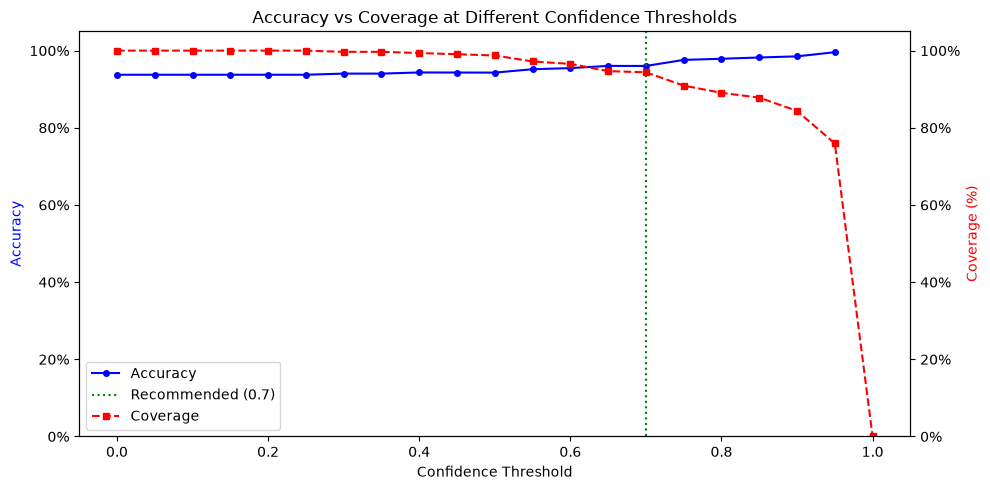


 Threshold   Accuracy   Coverage
----------------------------------
      0.00     93.75%    100.00%
      0.05     93.75%    100.00%
      0.10     93.75%    100.00%
      0.15     93.75%    100.00%
      0.20     93.75%    100.00%
      0.25     93.75%    100.00%
      0.30     94.04%     99.69%
      0.35     94.04%     99.69%
      0.40     94.34%     99.38%
      0.45     94.32%     99.06%
      0.50     94.30%     98.75%
      0.55     95.18%     97.19%
      0.60     95.47%     96.56%
      0.65     96.04%     94.69%
      0.70     96.03%     94.38% ◀ recommended
      0.75     97.59%     90.94%
      0.80     97.89%     89.06%
      0.85     98.22%     87.81%
      0.90     98.52%     84.38%
      0.95     99.59%     75.94%
      1.00      N/A        0.00%

✅ Ambang yang digunakan pada sistem: 0.7


In [23]:
# ============================================
# CONFIDENCE THRESHOLD ANALYSIS
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Prediksi probabilitas pada test set
y_pred_proba_all = model.predict(X_test, verbose=0)
y_pred_class_all = np.argmax(y_pred_proba_all, axis=1)
y_conf_all       = np.max(y_pred_proba_all, axis=1)

thresholds   = np.arange(0.0, 1.01, 0.05)
accs, covers = [], []

for thresh in thresholds:
    mask = y_conf_all >= thresh
    n_covered = mask.sum()
    if n_covered == 0:
        accs.append(np.nan)
    else:
        accs.append(accuracy_score(y_test[mask], y_pred_class_all[mask]))
    covers.append(n_covered / len(y_test))

# Plot
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.plot(thresholds, accs,   "b-o", markersize=4, label="Accuracy")
ax2.plot(thresholds, covers, "r--s", markersize=4, label="Coverage")

ax1.set_xlabel("Confidence Threshold")
ax1.set_ylabel("Accuracy",  color="b")
ax2.set_ylabel("Coverage (%)", color="r")
ax1.set_ylim(0, 1.05)
ax2.set_ylim(0, 1.05)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f"{v:.0%}"))
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f"{v:.0%}"))

# Garis ambang yang direkomendasikan
RECOMMENDED_THRESH = 0.70
ax1.axvline(RECOMMENDED_THRESH, color="green", linestyle=":", linewidth=1.5,
            label=f"Recommended ({RECOMMENDED_THRESH})")

ax1.set_title("Accuracy vs Coverage at Different Confidence Thresholds")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower left")
plt.tight_layout()
plt.show()

# Tabel ringkasan
print(f"\n{'Threshold':>10} {'Accuracy':>10} {'Coverage':>10}")
print("-" * 34)
for t, a, c in zip(thresholds, accs, covers):
    flag = " ◀ recommended" if abs(t - RECOMMENDED_THRESH) < 1e-9 else ""
    acc_str = f"{a:.2%}" if not np.isnan(a) else "   N/A  "
    print(f"{t:>10.2f} {acc_str:>10} {c:>10.2%}{flag}")

print(f"\n✅ Ambang yang digunakan pada sistem: {RECOMMENDED_THRESH}")


## 21. Inference Time Evaluation

In [24]:
# ============================================
# INFERENCE TIME EVALUATION
# ============================================

import time
import numpy as np

N_RUNS = 50   # jumlah pengulangan untuk rata-rata

# ── A. Waktu prediksi model (satu sekuens) ──
single_seq = X_test[:1]   # shape (1, 30, 225)

# Warmup
_ = model.predict(single_seq, verbose=0)

times_single = []
for _ in range(N_RUNS):
    t0 = time.perf_counter()
    model.predict(single_seq, verbose=0)
    times_single.append(time.perf_counter() - t0)

mean_single = np.mean(times_single) * 1000   # ms
std_single  = np.std(times_single)  * 1000

print("=" * 55)
print("  Inference Time — Model Prediction (1 sekuens)")
print("=" * 55)
print(f"  Mean   : {mean_single:.2f} ms")
print(f"  Std    : {std_single:.2f} ms")
print(f"  Min    : {np.min(times_single)*1000:.2f} ms")
print(f"  Max    : {np.max(times_single)*1000:.2f} ms")
print(f"  FPS ekuivalen: {1000/mean_single:.1f} pred/s")

# ── B. Waktu pipeline penuh (baca video → prediksi) ──
import random
random.seed(SEED)
sample_paths = random.sample(list(df["video_path"]), min(10, len(df)))

times_full = []
for vp in sample_paths:
    t0 = time.perf_counter()
    frames = sample_video_frames(str(vp))
    if frames is None:
        continue
    seq  = extract_landmarks(frames)
    seq  = np.expand_dims(seq.astype(np.float32), 0)
    proba = model.predict(seq, verbose=0)
    times_full.append(time.perf_counter() - t0)

mean_full = np.mean(times_full) * 1000
std_full  = np.std(times_full)  * 1000

print()
print("=" * 55)
print("  Inference Time — Pipeline Penuh (video→prediksi)")
print("=" * 55)
print(f"  Mean   : {mean_full:.2f} ms")
print(f"  Std    : {std_full:.2f} ms")
print(f"  Min    : {np.min(times_full)*1000:.2f} ms")
print(f"  Max    : {np.max(times_full)*1000:.2f} ms")
print(f"  Sampel : {len(times_full)} video")

# ── C. Breakdown pipeline ──
# Satu video sample untuk breakdown
vp = sample_paths[0]

t_read = time.perf_counter()
frames = sample_video_frames(str(vp))
t_read = time.perf_counter() - t_read

t_lm = time.perf_counter()
seq  = extract_landmarks(frames)
t_lm = time.perf_counter() - t_lm

t_pred = time.perf_counter()
model.predict(np.expand_dims(seq.astype(np.float32), 0), verbose=0)
t_pred = time.perf_counter() - t_pred

total = t_read + t_lm + t_pred
print()
print("=" * 55)
print("  Breakdown Pipeline (1 video sample):")
print("=" * 55)
print(f"  1. Baca & sample frame : {t_read*1000:>8.2f} ms  ({t_read/total*100:.1f}%)")
print(f"  2. Ekstraksi landmark  : {t_lm*1000:>8.2f} ms  ({t_lm/total*100:.1f}%)")
print(f"  3. Prediksi model      : {t_pred*1000:>8.2f} ms  ({t_pred/total*100:.1f}%)")
print(f"  ─────────────────────────────────────────")
print(f"  Total                  : {total*1000:>8.2f} ms")


  Inference Time — Model Prediction (1 sekuens)
  Mean   : 99.63 ms
  Std    : 5.08 ms
  Min    : 92.77 ms
  Max    : 126.08 ms
  FPS ekuivalen: 10.0 pred/s

  Inference Time — Pipeline Penuh (video→prediksi)
  Mean   : 2636.99 ms
  Std    : 278.06 ms
  Min    : 2140.69 ms
  Max    : 3116.35 ms
  Sampel : 10 video

  Breakdown Pipeline (1 video sample):
  1. Baca & sample frame :   592.59 ms  (21.5%)
  2. Ekstraksi landmark  :  2065.48 ms  (74.8%)
  3. Prediksi model      :   104.32 ms  (3.8%)
  ─────────────────────────────────────────
  Total                  :  2762.40 ms


## 22. Final Results and Conclusion

╔══════════════════════════════════════════════════════╗
║          SignBridge AI — FINAL RESULTS               ║
╠══════════════════════════════════════════════════════╣
║  DATASET                                             ║
║    Dataset      : WL-BISINDO                         ║
║    Kelas isyarat: 32                                 ║
║    Train samples: 1024                               ║
║    Val samples  : 256                                ║
║    Test samples : 320                                ║
╠══════════════════════════════════════════════════════╣
║  MODEL ARCHITECTURE                                  ║
║    Masking → LSTM(128) → Dropout(0.3)               ║
║    → LSTM(64) → Dropout(0.3)                        ║
║    → Dense(64,relu) → Dropout(0.2)                  ║
║    → Dense(32, softmax)                        ║
║    Total params : 244,384                           ║
╠══════════════════════════════════════════════════════╣
║  TRAINING                              

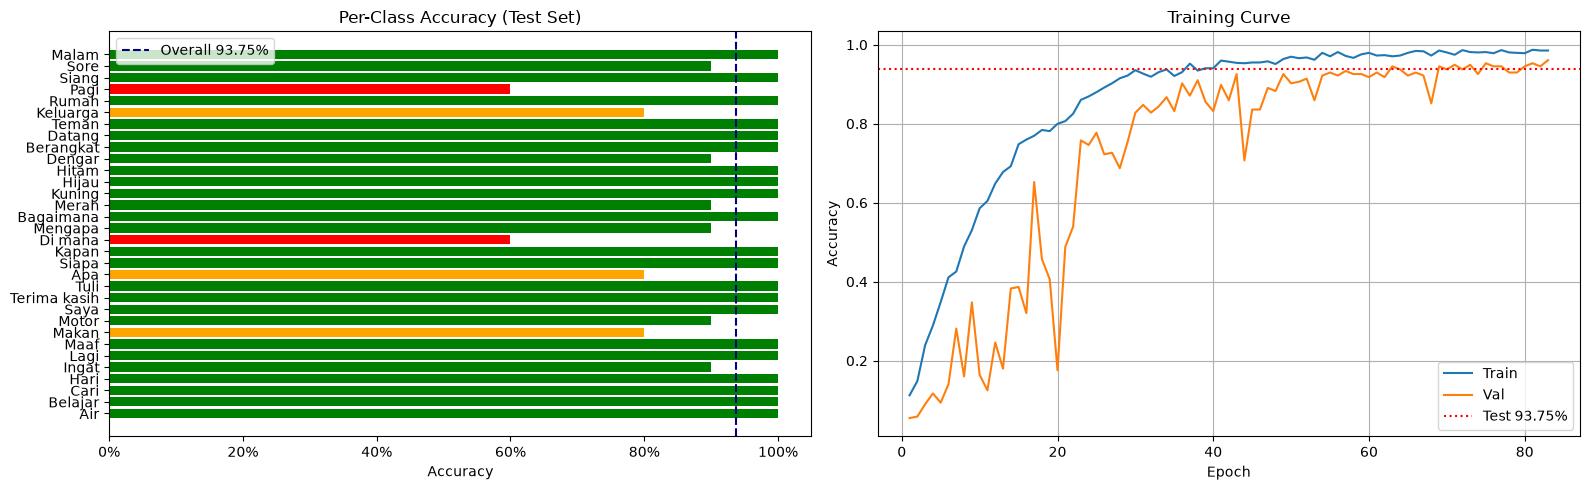


📊 Grafik disimpan: c:\Users\Ryan\Documents\JURNEY KAMPUS\S7\SISTEM CERDAS\proyek\bisindo\models\final_results.png

✅ Notebook SignBridge AI selesai!


In [25]:
# ============================================
# FINAL RESULTS AND CONCLUSION
# ============================================

from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Hitung metrik final
y_pred_final = np.argmax(model.predict(X_test, verbose=0), axis=1)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
f1_macro  = f1_score(y_test, y_pred_final, average="macro")
f1_weighted = f1_score(y_test, y_pred_final, average="weighted")

# ══════════════════════════════════════════════════════════════
print("╔══════════════════════════════════════════════════════╗")
print("║          SignBridge AI — FINAL RESULTS               ║")
print("╠══════════════════════════════════════════════════════╣")
print("║  DATASET                                             ║")
print(f"║    Dataset      : WL-BISINDO                         ║")
print(f"║    Kelas isyarat: {NUM_CLASSES:<35d}║")
print(f"║    Train samples: {len(y_train):<35d}║")
print(f"║    Val samples  : {len(y_val):<35d}║")
print(f"║    Test samples : {len(y_test):<35d}║")
print("╠══════════════════════════════════════════════════════╣")
print("║  MODEL ARCHITECTURE                                  ║")
print("║    Masking → LSTM(128) → Dropout(0.3)               ║")
print("║    → LSTM(64) → Dropout(0.3)                        ║")
print("║    → Dense(64,relu) → Dropout(0.2)                  ║")
print(f"║    → Dense({NUM_CLASSES}, softmax)                        ║")
print(f"║    Total params : {model.count_params():<34,d}║")
print("╠══════════════════════════════════════════════════════╣")
print("║  TRAINING                                            ║")
print(f"║    Epochs dijalankan : {len(history.history['accuracy']):<30d}║")
print(f"║    Best val loss     : {min(history.history['val_loss']):<30.4f}║")
print(f"║    Best val accuracy : {max(history.history['val_accuracy']):<30.4f}║")
print("╠══════════════════════════════════════════════════════╣")
print("║  EVALUATION (Test Set)                               ║")
print(f"║    Test Loss        : {test_loss:<31.4f}║")
print(f"║    Test Accuracy    : {test_acc:.4f}  ({test_acc*100:.2f}%)            ║")
print(f"║    F1 Macro         : {f1_macro:<31.4f}║")
print(f"║    F1 Weighted      : {f1_weighted:<31.4f}║")
print("╠══════════════════════════════════════════════════════╣")
print("║  KETERBATASAN                                        ║")
print("║  • Model dilatih pada data studio (kondisi ideal)   ║")
print("║  • Performa mungkin turun di lingkungan nyata       ║")
print("║  • Split acak (bukan signer-independent)            ║")
print("║  • Hanya 32 kosakata BISINDO                        ║")
print("╠══════════════════════════════════════════════════════╣")
print("║  RENCANA PENGEMBANGAN                                ║")
print("║  • Data augmentasi (noise, time-warp, mirror)       ║")
print("║  • Arsitektur: Transformer / Attention LSTM         ║")
print("║  • Perluasan kosakata (lebih banyak kelas)          ║")
print("║  • Signer-independent split secara eksplisit       ║")
print("║  • Pengenalan kalimat (bukan per-kata)              ║")
print("║  • Deployment mobile (TFLite / ONNX)               ║")
print("╚══════════════════════════════════════════════════════╝")

# ── Grafik ringkasan per kelas ──
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

per_class_acc = []
for cls_idx in range(NUM_CLASSES):
    mask = y_test == cls_idx
    if mask.sum() == 0:
        per_class_acc.append(0.0)
    else:
        per_class_acc.append(accuracy_score(y_test[mask], y_pred_final[mask]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Bar chart per-class accuracy
axes[0].barh(gloss_names, per_class_acc, color=[
    "green" if a >= 0.9 else "orange" if a >= 0.7 else "red"
    for a in per_class_acc
])
axes[0].axvline(test_acc, color="navy", linestyle="--", label=f"Overall {test_acc:.2%}")
axes[0].set_xlabel("Accuracy")
axes[0].set_title("Per-Class Accuracy (Test Set)")
axes[0].set_xlim(0, 1.05)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f"{v:.0%}"))
axes[0].legend()

# Training curve
epochs = range(1, len(history.history["accuracy"]) + 1)
axes[1].plot(epochs, history.history["accuracy"],    label="Train")
axes[1].plot(epochs, history.history["val_accuracy"], label="Val")
axes[1].axhline(test_acc, color="red", linestyle=":", label=f"Test {test_acc:.2%}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training Curve")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(MODEL_DIR / "final_results.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\n📊 Grafik disimpan: {MODEL_DIR / 'final_results.png'}")
print("\n✅ Notebook SignBridge AI selesai!")
